In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('adult_income.csv')
df.sample(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
39669,24,Private,278391,Assoc-acdm,12,Never-married,Sales,Own-child,White,Male,0,0,30,United-States,<=50K.
10951,38,Private,80771,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,0,40,United-States,>50K
574,27,Private,158156,Doctorate,16,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,70,United-States,<=50K


In [33]:
df.shape
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [34]:
# removing extra white-space with "?" 
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [35]:
df.replace("?",np.nan,inplace=True)

In [36]:
# print((df=="?").sum()) and
df.isnull().sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

In [37]:
df.dropna(inplace=True)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45222 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   fnlwgt          45222 non-null  int64 
 3   education       45222 non-null  object
 4   education-num   45222 non-null  int64 
 5   marital-status  45222 non-null  object
 6   occupation      45222 non-null  object
 7   relationship    45222 non-null  object
 8   race            45222 non-null  object
 9   sex             45222 non-null  object
 10  capital-gain    45222 non-null  int64 
 11  capital-loss    45222 non-null  int64 
 12  hours-per-week  45222 non-null  int64 
 13  native-country  45222 non-null  object
 14  income          45222 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.5+ MB


In [73]:
df.sample(2)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
29569,18,Private,232082,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,<=50K
10798,61,Federal-gov,178312,Some-college,10,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,40,United-States,<=50K


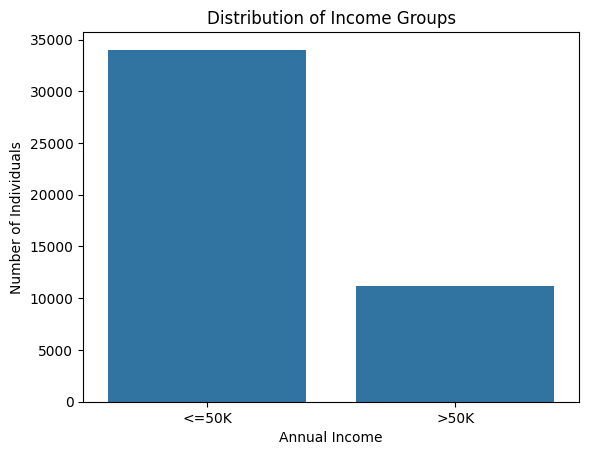

In [76]:
sns.countplot(data=df, x="income")
plt.title("Distribution of Income Groups")
plt.xlabel("Annual Income")
plt.ylabel("Number of Individuals")
plt.show()

income,<=50K,>50K
has_capital_gain,,
False,78.680730,21.319270
True,37.335092,62.664908


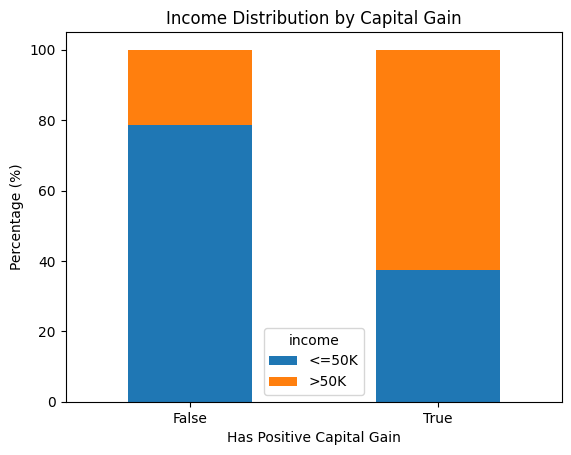

In [78]:
df["has_capital_gain"] = df["capital-gain"] > 0

gain_income = pd.crosstab(
    df["has_capital_gain"],
    df["income"],
    normalize="index"
) * 100

display(gain_income)

gain_income.plot(kind="bar", stacked=True)
plt.title("Income Distribution by Capital Gain")
plt.ylabel("Percentage (%)")
plt.xlabel("Has Positive Capital Gain")
plt.xticks(rotation=0)
plt.show()

income,<=50K,>50K
education,,
10th,93.295176,6.704824
11th,94.502779,5.497221
12th,92.547660,7.452340
1st-4th,96.396396,3.603604
5th-6th,95.100223,4.899777
7th-8th,93.317132,6.682868
9th,94.378698,5.621302
Assoc-acdm,73.589914,26.410086
Assoc-voc,74.272588,25.727412


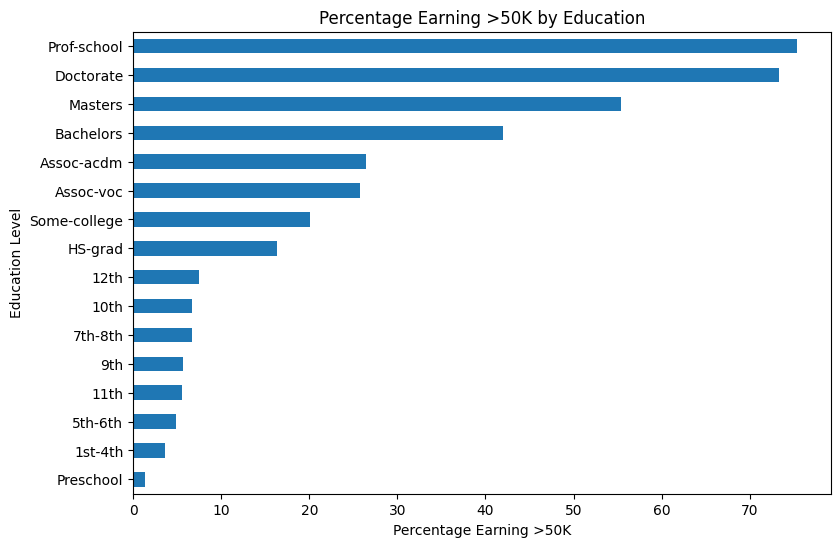

In [79]:
education_income = pd.crosstab(
    df["education"],
    df["income"],
    normalize="index"
) * 100

display(education_income)

education_income[">50K"].sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Percentage Earning >50K by Education")
plt.xlabel("Percentage Earning >50K")
plt.ylabel("Education Level")
plt.show()

income,<=50K,>50K
age_group,,
16-25,98.068949,1.931051
26-35,80.867981,19.132019
36-45,64.949442,35.050558
46-55,60.345262,39.654738
56-65,67.762326,32.237674
66+,78.273810,21.726190


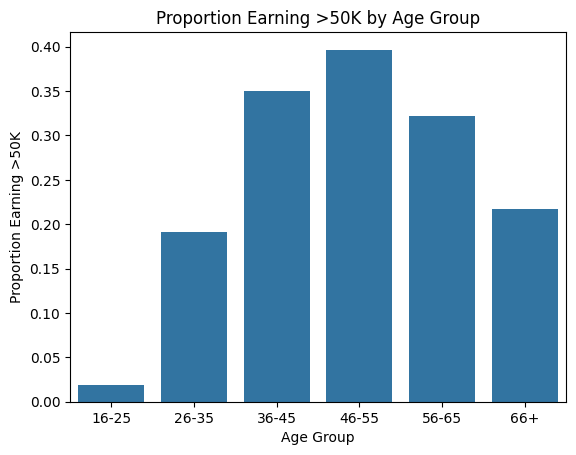

In [80]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[15, 25, 35, 45, 55, 65, 100],
    labels=["16-25", "26-35", "36-45",
            "46-55", "56-65", "66+"]
)

age_income = pd.crosstab(
    df["age_group"],
    df["income"],
    normalize="index"
) * 100

display(age_income)

sns.barplot(
    data=df,
    x="age_group",
    y=(df["income"] == ">50K").astype(int),
    errorbar=None
)

plt.title("Proportion Earning >50K by Age Group")
plt.ylabel("Proportion Earning >50K")
plt.xlabel("Age Group")
plt.show()

In [ ]:
#* Among all features, education level is having a great impact on income, as seen in graph.
#* Capital-gain comes at second, as more people who has better capital-gain, are having income >50K then those with no capital-gain
#* Age comes 3rd, middle-aged people has more income then young and older people

#* ranking: education level > capital_gain > age

## Qustion 2 - Preprocessing Pipeline Design

In [39]:
df['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [40]:
#* the column 'income' contains some values with a tailing dot(.), removing those extra dot(.) and possible white-spaces as well

df["income"] = (
    df["income"]
    .str.strip()
    .str.rstrip(".")
)

In [41]:
df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [42]:
numerical_cols = ['age','education-num','capital-gain','capital-loss'];

ordinal_cats = ['income']; #? there's only two type of of income, ">50K" and "<=50K", so using this feature as a ordinal category

nominal_cats = ['workclass','marital-status','occupation','relationship','race','sex','native-country'];

income_order = ['<=50K','>50K'];

# 'hours-per-week' is the target column here

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline

In [44]:
# imputing missing numerical data with the average of existing data.
# There is no missing values in numerical features
numrical_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='mean')),
        ("scaler",StandardScaler())
    ]
)

# imputing 'income', which is the only 'ordinal' category, with the most_frequent value
# there is no missing values of 'income' in the dataset
ordinal_cats_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='most_frequent')),
        ("encoder",OrdinalEncoder(categories=[income_order]))
    ]
)

# 'workclass', 'occupation' and 'native-country' has many missing values, imputing them all with the most frequent values
nominal_cats_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='most_frequent')),
        ("encoder",OneHotEncoder(sparse_output=False,handle_unknown='ignore'))
    ]
)

In [45]:
from sklearn.compose import ColumnTransformer

preprocessor =ColumnTransformer(
    transformers=[
        ("preprocessor",numrical_pipe,numerical_cols),
        ("ordinal_cats_pipe",ordinal_cats_pipe,ordinal_cats),
        ("nominal_cats_pipe",nominal_cats_pipe,nominal_cats)
    ],
    remainder='drop'
)

## Question 3 - Regression Modeling & Evaluation

In [46]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['hours-per-week']);
y = df['hours-per-week'];

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [47]:
x_train.shape
x_test.shape

(9045, 14)

### Linear Regression

In [48]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

linearRegPipe = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("lr_model",LinearRegression())
    ]
)

linearRegPipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('lr_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessor', ...), ('ordinal_cats_pipe', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

In [49]:
#? predicting by the linear refression model
y_predicted = linearRegPipe.predict(x_test)
y_predicted

array([47.20383656, 44.5769079 , 40.0989289 , ..., 39.23861517,
       38.9603813 , 38.66938255], shape=(9045,))

In [50]:
# performace
print(f"Mean Absolute Error(MAE): {round(mean_absolute_error(y_test,y_predicted),4)}",)
print(f"Mean Squared Error(MSE): {round(mean_squared_error(y_test,y_predicted),4)}",)
print(f"R2 Score(R2): {round(r2_score(y_test,y_predicted),4)}",)

Mean Absolute Error(MAE): 7.5225
Mean Squared Error(MSE): 119.6676
R2 Score(R2): 0.1804


### SGD Regressor

In [51]:
sgdRegPipe = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("sgd_model",SGDRegressor())
    ]
)

sgdRegPipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('sgd_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessor', ...), ('ordinal_cats_pipe', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

In [52]:
#? predicting by the sgd regressor model
y_predicted = sgdRegPipe.predict(x_test)
y_predicted

array([46.6847839 , 44.56870787, 39.42586679, ..., 39.30705068,
       38.4858174 , 38.46464883], shape=(9045,))

In [53]:
# performance
print(f"Mean Absolute Error(MAE): {round(mean_absolute_error(y_test,y_predicted),4)}",)
print(f"Mean Squared Error(MSE): {round(mean_squared_error(y_test,y_predicted),4)}",)
print(f"R2 Score(R2): {round(r2_score(y_test,y_predicted),4)}",)

Mean Absolute Error(MAE): 7.4999
Mean Squared Error(MSE): 119.7
R2 Score(R2): 0.1802


In [54]:
#* The MSE of Linear regression model is 124.2412 and sgdregressor is 124.4288, the Linear Regression model has mean absolute error 7.707 and r2 score is 0.1897, and the sgdregressor model has mean absolute error 7.6943 and r2 score is 0.1884,,,from this figures, the linear regression model seems performed somewhat better.

## Question 4 - Classification Pipeline & Error Analysis  

In [55]:
numerical_cols = ['age','education-num','capital-gain','capital-loss','hours-per-week'];
nominal_cats = ['workclass','marital-status','occupation','relationship','race','sex','native-country'];

Preprocessing pipelines

In [56]:
numrical_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='mean')),
        ("scaler",StandardScaler())
    ]
)

nominal_cats_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='most_frequent')),
        ("encoder",OneHotEncoder(sparse_output=False,handle_unknown='ignore'))
    ]
)

In [57]:
from sklearn.compose import ColumnTransformer

preprocessor =ColumnTransformer(
    transformers=[
        ("preprocessor",numrical_pipe,numerical_cols),
        ("nominal_cats_pipe",nominal_cats_pipe,nominal_cats)
    ],
    remainder='drop'
)

In [58]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['income'])
y = df['income']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42,stratify=y);

In [59]:
x_train.shape

(36177, 14)

In [60]:
from sklearn.preprocessing import LabelEncoder

targetEncoder = LabelEncoder()

y_train = targetEncoder.fit_transform(y_train)
y_test = targetEncoder.transform(y_test)

In [61]:
from sklearn.linear_model import LogisticRegression

logisticRegresModel = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LogisticRegression(class_weight='balanced',max_iter=1000))
    ]
)

logisticRegresModel

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessor', ...), ('nominal_cats_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the di

In [62]:
logisticRegresModel.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessor', ...), ('nominal_cats_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the di

In [63]:
y_predicted = logisticRegresModel.predict(x_test)
y_predicted

array([0, 1, 0, ..., 0, 0, 1], shape=(9045,))

In [64]:
logisticRegresModel.predict_proba(x_test)

array([[9.93988552e-01, 6.01144758e-03],
       [7.39808572e-04, 9.99260191e-01],
       [7.59714074e-01, 2.40285926e-01],
       ...,
       [9.90833320e-01, 9.16667976e-03],
       [5.19889120e-01, 4.80110880e-01],
       [2.98102164e-01, 7.01897836e-01]], shape=(9045, 2))

In [65]:
from sklearn.metrics import accuracy_score,precision_score,recall_score

accuracy = accuracy_score(y_test,y_predicted)
print(f"Accuracy: {accuracy}")
precision = precision_score(y_test,y_predicted)
print(f"Precision: {precision}",)
recall = recall_score(y_test,y_predicted)
print(f"Recall: {recall}",)

Accuracy: 0.807739082365948
Precision: 0.5778878909879219
Recall: 0.8322925958965209


## Question 5 - Hyperparameter Tuning & Model Comparison

In [66]:
numerical_cols = ['age','education-num','capital-gain','capital-loss','hours-per-week'];
nominal_cats = ['workclass','marital-status','occupation','relationship','race','sex','native-country'];

numrical_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='mean')),
        ("scaler",StandardScaler())
    ]
)

nominal_cats_pipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy='most_frequent')),
        ("encoder",OneHotEncoder(sparse_output=False,handle_unknown='ignore'))
    ]
)

preprocessor =ColumnTransformer(
    transformers=[
        ("preprocessor",numrical_pipe,numerical_cols),
        ("nominal_cats_pipe",nominal_cats_pipe,nominal_cats)
    ],
    remainder='drop'
)

In [67]:
x = df.drop(columns=['income'])
y = df['income']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42,stratify=y);

In [68]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [69]:
x_train.shape

(36177, 14)

In [70]:
x_test.shape

(9045, 14)

In [71]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("knn",KNeighborsClassifier())
    ]
)

knn_model.fit(x_train,y_train_encoded)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessor', ...), ('nominal_cats_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diff

In [72]:
from sklearn.model_selection import GridSearchCV

gridParams = {
    "knn__n_neighbors":[100,125,150,175,180,185,200],
    "knn__weights": ['distance','uniform'],
    "knn__p":[1,2]
}

gridSearch = GridSearchCV(
    estimator=knn_model,
    param_grid=gridParams,
    cv=5
)

# gridSearch.fit(x_train, y_train_encoded)